In [4]:
from rdkit import Chem

()
(14, 1, 13, 8, 7, 6, 5, 4, 3, 17, 16, 15)
N1: 15, N2: 4
C1: 6, C2: 5


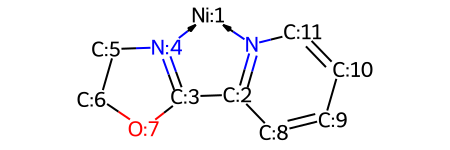

In [21]:
sdf_path = '/home/aconner/mlr/orca_descriptors/DATA/LNiH2_library_001_to_download_2026_03_24/AATATIAROAAKIN-SNVBAGLBSA-N/conf_2/optimization.sdf'

#way mol file is creating in atom_numbering code
try:
    suppl = Chem.SDMolSupplier(sdf_path, removeHs=False)
    mol = next((m for m in suppl if m is not None), None)
except:
    print (f'bad input file for {sdf_path}')

#two pays of writing Ni-bound PyOx (C=C vs N=C in SMILES)
pyox_structure = Chem.MolFromSmiles('[N]1([Ni]2)=C(C3=[N]2CCO3)C=CC=C1')
pyox_structure2 = Chem.MolFromSmiles('N1([Ni]2)C=CC=CC1=C3N2CCO3')

sub_structure = mol.GetSubstructMatch(pyox_structure)
print(sub_structure)
sub_structure2 = mol.GetSubstructMatch(pyox_structure2)
print(sub_structure2)

if len(sub_structure2) > 0:
    print(f"N1: {sub_structure2[0] + 1}, N2: {sub_structure2[8] + 1}")
    print(f"C1: {sub_structure2[6] + 1}, C2: {sub_structure2[7] + 1}")
elif len(sub_structure) > 0:
    print(f"N1: {sub_structure[0] + 1}, N2: {sub_structure[4] + 1}")
    print(f"C1: {sub_structure[2] + 1}, C2: {sub_structure[3] + 1}")
else:
    print("No match found for either PyOx structure. Atom numbers will not be adjusted.")

#print(f"N1: {patt[2]}, N2: {patt[7]}")
for at in pyox_structure.GetAtoms():
    #print(at.GetSymbol())
    at.SetAtomMapNum(at.GetIdx())

for at in mol.GetAtoms():
    #print(at.GetSymbol())
    at.SetAtomMapNum(at.GetIdx())


pyox_structure


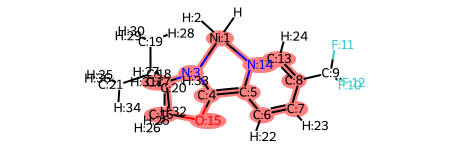

In [20]:
mol

new push